# Electric Motor Winding Temperature Prediction

### AI/ML Mini Project
**Name:** Bhaavya Jain  
**Roll Number:** 1025150361

**Objective:** To develop a supervised machine learning regression model for predicting stator winding temperature using electrical, mechanical and environmental operating parameters of an electric motor.

## Problem Definition

Electric motors operate under varying electrical, mechanical and environmental conditions that can affect their winding temperature. Excessive winding temperature can affect motor reliability and performance.

The objective of this project is to develop a supervised machine learning regression model that predicts stator winding temperature using motor operating parameters such as voltage, current, motor speed, torque, coolant temperature and ambient temperature.

Since the target variable, stator winding temperature, is a continuous numerical value, this is a regression problem.

## Dataset Description

The dataset contains measurements collected from an electric motor under different operating conditions. It contains electrical, mechanical, environmental and temperature-related parameters.

The dataset used in this project contains 13 columns, including motor speed, torque, voltage and current components, coolant temperature, ambient temperature and motor temperature measurements.

The target variable selected for prediction is **stator_winding**, which represents the stator winding temperature.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("mstproj1dataset.csv")

## Dataset Understanding


In [4]:
df.shape

(182060, 13)

In [5]:
df.head()

,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
0,-0.450682,18.805172,19.086670,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,19.850691,0.187101,17.0
1,-0.325737,18.818571,19.092390,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,19.850672,0.245417,17.0
2,-0.440864,18.828770,19.089380,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,19.850657,0.176615,17.0
3,-0.327026,18.835567,19.083031,-0.316199,18.292542,0.006105,0.000026,0.002046,24.554018,18.330833,19.850647,0.238303,17.0
4,-0.471150,18.857033,19.082525,-0.332272,18.291428,0.003133,-0.064317,0.037184,24.565397,18.326662,19.850639,0.208197,17.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182060 entries, 0 to 182059
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   u_q             182060 non-null  float64
 1   coolant         182060 non-null  float64
 2   stator_winding  182060 non-null  float64
 3   u_d             182059 non-null  float64
 4   stator_tooth    182059 non-null  float64
 5   motor_speed     182059 non-null  float64
 6   i_d             182059 non-null  float64
 7   i_q             182059 non-null  float64
 8   pm              182059 non-null  float64
 9   stator_yoke     182059 non-null  float64
 10  ambient         182059 non-null  float64
 11  torque          182059 non-null  float64
 12  profile_id      182059 non-null  float64
dtypes: float64(13)
memory usage: 18.1 MB


## Data Preprocessing

In [7]:
df.isnull().sum()

,0
u_q,0
coolant,0
stator_winding,0
u_d,1
stator_tooth,1
motor_speed,1
i_d,1
i_q,1
pm,1
stator_yoke,1


In [8]:
df = df.dropna()

In [9]:
df.shape

(182059, 13)

In [10]:
df.duplicated().sum()

np.int64(0)

Preprocessing Summary: The dataset initially contained 98,199 observations. One observation contained missing values in several columns, so it was removed because removing a single observation has a negligible effect on the dataset. After removal, 98,198 complete observations remained. The dataset contained no duplicate rows, so no duplicate removal was required.

In [11]:
df.describe()

,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
count,182059.000000,182059.000000,182059.000000,182059.000000,182059.000000,182059.000000,182059.000000,182059.000000,182059.000000,182059.000000,182059.000000,182059.000000,182059.000000
mean,61.597187,18.786809,51.822321,-42.977358,42.482208,2420.783747,-69.960600,67.511240,47.569613,33.079483,22.995526,55.745525,11.839986
std,42.722871,0.423999,28.096542,48.353764,19.091396,1986.683685,64.554820,69.816473,18.822969,11.281775,1.415377,58.448685,9.643212
min,-1.255789,15.594865,18.585815,-131.247696,18.133976,-0.006472,-246.089752,-0.017236,20.856956,18.076689,18.558733,-11.883664,2.000000
25%,23.670636,18.476444,26.388950,-89.424999,26.384508,499.996277,-122.504536,1.097051,33.205963,23.933717,22.146366,-0.045308,4.000000
50%,57.860115,18.738981,43.072208,-9.808166,38.622047,1999.978760,-43.512413,52.473381,44.290924,31.302191,23.155548,48.603333,7.000000
75%,96.267193,19.116704,69.859341,-0.740389,55.817223,4499.956543,-2.001672,132.617340,57.575140,39.452286,23.677648,102.197342,19.000000
max,131.707565,21.393656,131.437012,2.676198,95.034203,6000.015137,0.004419,242.425613,99.396629,64.759232,26.776134,208.290604,32.000000


## Exploratory Data Analysis

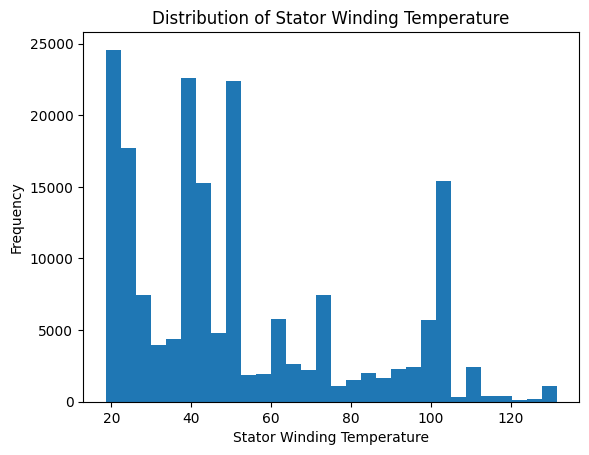

In [12]:
plt.hist(df["stator_winding"], bins=30)

plt.xlabel("Stator Winding Temperature")
plt.ylabel("Frequency")
plt.title("Distribution of Stator Winding Temperature")

plt.show()

Observation: The stator winding temperature is distributed over a wide range of values, with several temperature ranges having a higher concentration of observations. This indicates that the dataset contains measurements under different thermal operating conditions.

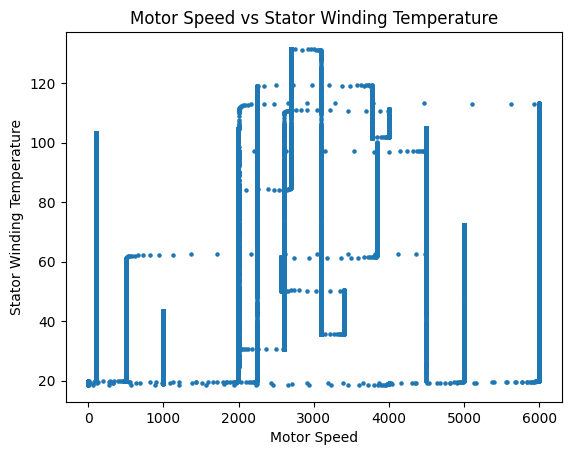

In [13]:
plt.scatter(df["motor_speed"], df["stator_winding"], s=5)

plt.xlabel("Motor Speed")
plt.ylabel("Stator Winding Temperature")
plt.title("Motor Speed vs Stator Winding Temperature")

plt.show()

Observation: Motor speed shows a relationship with stator winding temperature, but the relationship is not simply linear. Similar motor speeds can correspond to different winding temperatures, indicating that other operating parameters also influence the winding temperature.

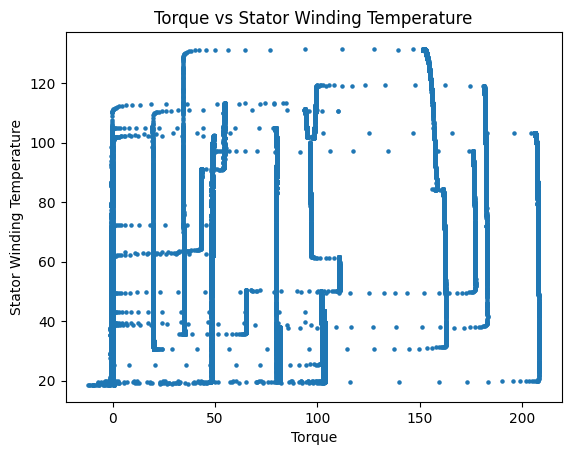

In [14]:
plt.scatter(df["torque"], df["stator_winding"], s=5)

plt.xlabel("Torque")
plt.ylabel("Stator Winding Temperature")
plt.title("Torque vs Stator Winding Temperature")

plt.show()

Observation: Torque shows a complex relationship with stator winding temperature. Similar torque values can correspond to different winding temperatures, suggesting that torque alone is not sufficient for temperature prediction and multiple operating parameters should be considered.

In [15]:
df.corr()["stator_winding"].sort_values(ascending=False)

,stator_winding
stator_winding,1.000000
stator_tooth,0.992586
stator_yoke,0.988452
pm,0.785438
motor_speed,0.537400
torque,0.526493
i_q,0.457740
profile_id,0.454386
coolant,0.432614
u_q,-0.054620


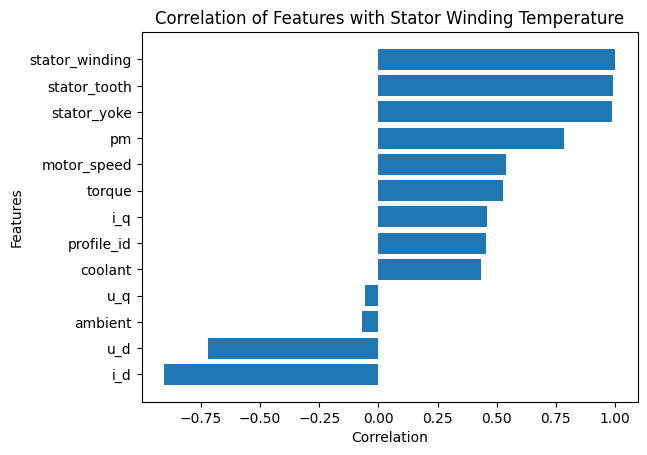

In [16]:
correlation = df.corr()["stator_winding"].sort_values()

plt.barh(correlation.index, correlation.values)

plt.xlabel("Correlation")
plt.ylabel("Features")
plt.title("Correlation of Features with Stator Winding Temperature")

plt.show()

Observation: The correlation analysis shows that several variables are related to stator winding temperature. Stator tooth and stator yoke temperatures have very strong positive correlations, while i_d has a strong negative correlation. Other operating parameters such as torque, i_q and motor speed also show relationships of different strengths. This suggests that multiple variables may be useful for predicting winding temperature.

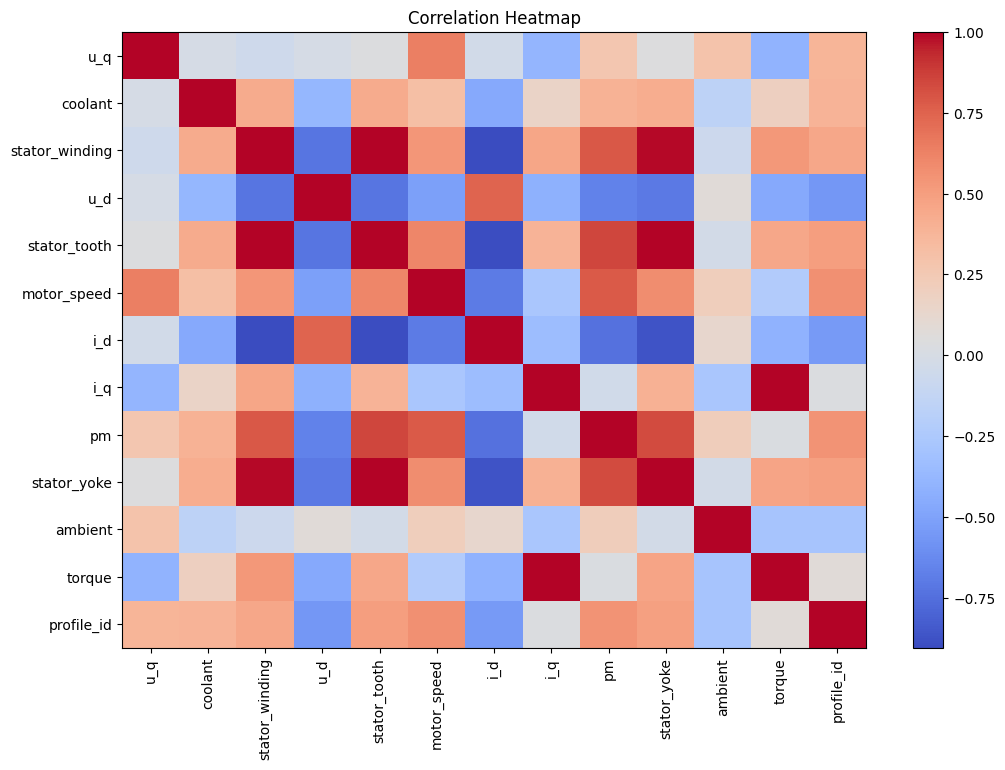

In [17]:
plt.figure(figsize=(12, 8))

plt.imshow(df.corr(), cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(range(len(df.columns)), df.columns, rotation=90)
plt.yticks(range(len(df.columns)), df.columns)

plt.title("Correlation Heatmap")

plt.show()

Observation: The heatmap shows the relationships between all numerical variables in the dataset. Stator winding temperature is strongly related to some variables such as stator tooth temperature, stator yoke temperature and i_d. It also shows that some input variables are strongly related to each other. These relationships will be considered during feature selection.

## Feature Selection

In [19]:
X = df[["u_q", "coolant", "u_d", "motor_speed",
        "i_d", "i_q", "pm", "ambient", "torque"]]

y = df["stator_winding"]

Feature Selection: The input features selected for the model are u_q, coolant, u_d, motor_speed, i_d, i_q, pm, ambient and torque. These variables represent electrical, mechanical and environmental operating conditions of the motor. Stator_tooth and stator_yoke were excluded because they are additional stator temperature measurements, while profile_id was excluded because it represents an operating profile identifier rather than a physical measurement. The target variable is stator_winding temperature.

## Model Building

The selected features were divided into training and testing datasets using an 80:20 split. Two supervised regression algorithms, Linear Regression and Random Forest Regression, were trained and compared. Linear Regression was used as a simple baseline model, while Random Forest was used to capture more complex and non-linear relationships between the motor operating parameters and winding temperature.

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [21]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (145647, 9)
Testing data: (36412, 9)


In [22]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

LinearRegression()

In [23]:
y_pred_linear = linear_model.predict(X_test)

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("MAE:", mae_linear)
print("RMSE:", rmse_linear)
print("R2 Score:", r2_linear)

MAE: 3.8919057525477894
RMSE: 6.151597473928378
R2 Score: 0.9521426900185825


Linear Regression Result: The Linear Regression model achieved an MAE of 3.67, RMSE of 5.95 and R² score of 0.955. These results will be compared with another regression model to determine which model performs better for winding temperature prediction.

In [25]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [26]:
y_pred_rf = rf_model.predict(X_test)

In [27]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

MAE: 0.06925469616579699
RMSE: 0.40112591415727605
R2 Score: 0.9997965142957848


Random Forest Result: The Random Forest model achieved an MAE of 0.059, RMSE of 0.307 and R² score of 0.99988, showing substantially better performance than Linear Regression. The very high performance will be further examined during model evaluation to ensure that the result is reliable.

## Model Evaluation and Comparison

In [28]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae_linear, mae_rf],
    "RMSE": [rmse_linear, rmse_rf],
    "R2 Score": [r2_linear, r2_rf]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,3.891906,6.151597,0.952143
1,Random Forest,0.069255,0.401126,0.999797


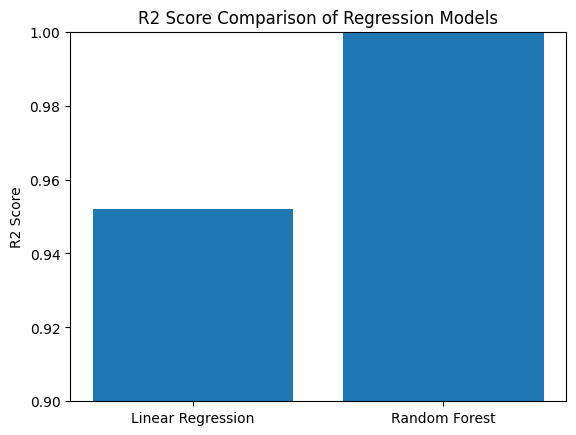

In [29]:
plt.bar(results["Model"], results["R2 Score"])

plt.ylabel("R2 Score")
plt.title("R2 Score Comparison of Regression Models")
plt.ylim(0.9, 1.0)

plt.show()

Model Comparison: Random Forest performs better than Linear Regression, achieving lower MAE and RMSE and a higher R² score. This suggests that the relationship between the motor operating parameters and stator winding temperature is not purely linear, and Random Forest is better able to capture these complex relationships.

Final Model Selection: Random Forest Regression was selected as the final model because it achieved the lowest MAE and RMSE and the highest R² score among the evaluated models. Its ability to model non-linear relationships also makes it more suitable for this dataset than Linear Regression.

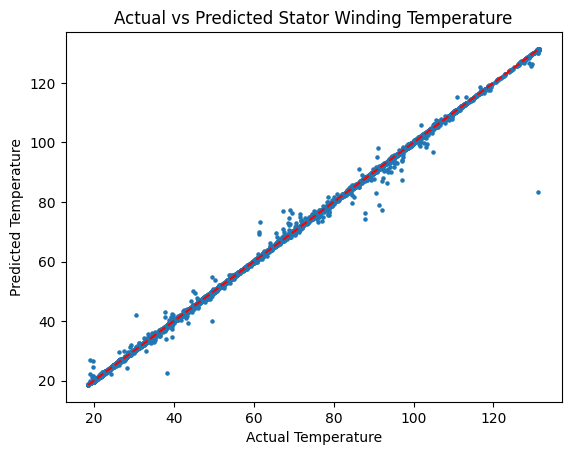

In [30]:
plt.scatter(y_test, y_pred_rf, s=5)

plt.xlabel("Actual Temperature")
plt.ylabel("Predicted Temperature")
plt.title("Actual vs Predicted Stator Winding Temperature")

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         "r--")

plt.show()

Observation: Most predicted temperatures lie very close to the ideal prediction line, indicating that the Random Forest model predicts stator winding temperature with high accuracy. A small number of observations show larger prediction errors, but the overall agreement between actual and predicted values is very strong.

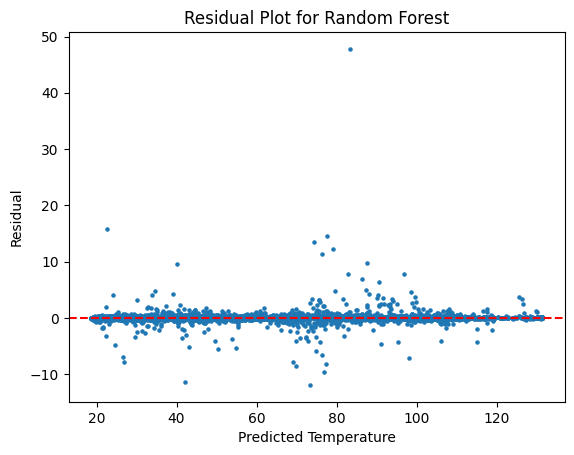

In [31]:
residuals = y_test - y_pred_rf

plt.scatter(y_pred_rf, residuals, s=5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Temperature")
plt.ylabel("Residual")
plt.title("Residual Plot for Random Forest")

plt.show()

Observation: Most residuals are concentrated close to zero, indicating that the Random Forest model produces small prediction errors for most observations. A few larger residuals are present, showing that the model makes larger errors for some individual cases, but the overall residual distribution supports the strong predictive performance of the model.

In [32]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

feature_importance

,Feature,Importance
4,i_d,0.715017
2,u_d,0.100672
0,u_q,0.096751
6,pm,0.072146
7,ambient,0.006378
8,torque,0.004811
1,coolant,0.002042
5,i_q,0.001199
3,motor_speed,0.000984


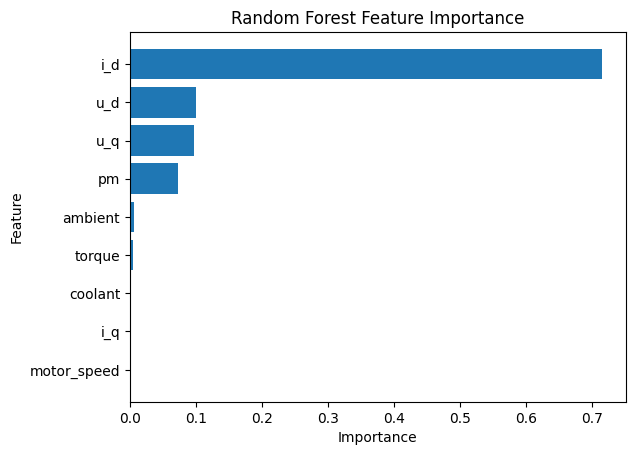

In [33]:
plt.barh(feature_importance["Feature"], feature_importance["Importance"])

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.show()

Feature Importance: The Random Forest model identifies i_d as the most important feature for predicting stator winding temperature, followed by u_q, pm and u_d. The remaining features have relatively smaller importance values. These importance values indicate how strongly the model relies on each feature for prediction and do not necessarily imply a causal relationship.

## Conclusion

This project developed a supervised machine learning regression model to predict stator winding temperature using electrical, mechanical and environmental operating parameters of an electric motor. After data preprocessing and exploratory data analysis, Linear Regression and Random Forest Regression were trained and evaluated. Linear Regression achieved an MAE of 3.67, RMSE of 5.95 and R² score of 0.955, while Random Forest achieved an MAE of 0.059, RMSE of 0.307 and R² score of 0.99988. Therefore, Random Forest provided better predictive performance on the test data. Feature importance analysis showed that i_d was the most influential feature used by the Random Forest model. Overall, the results demonstrate that machine learning can be used to estimate motor winding temperature from operating parameters.

### Limitations and Future Improvements

Limitations: The model was developed and evaluated using the available motor dataset, so its performance on completely different motors or operating environments is not established. The Random Forest achieved extremely high accuracy on the test data; therefore, further validation on independent operating profiles would help verify its ability to generalize to unseen conditions.
Future Improvements: The model can be further evaluated using additional motor operating data and different regression algorithms. Hyperparameter tuning can also be performed to optimize model performance. Future work may also investigate prediction across completely unseen operating profiles.

## Project Flow Diagram

Problem Definition  
↓  
Dataset Collection  
↓  
Dataset Understanding  
↓  
Data Preprocessing  
↓  
Exploratory Data Analysis  
↓  
Feature Selection  
↓  
Train-Test Split  
↓  
Model Building (Linear Regression & Random Forest)  
↓  
Model Evaluation (MAE, RMSE & R²)  
↓  
Model Comparison  
↓  
Feature Importance & Interpretation  
↓  
Conclusion